# 04.01 — Estratégia de entrada: 240 horas → próximas 24 horas

**Objetivo:** definir e materializar as janelas de previsão após o pré-processamento do `03_03`. Cada amostra recebe **10 dias anteriores com valores horários (240 passos)** e prevê **todas as 24 potências horárias seguintes**. O alvo é uma curva de potência em kW, e não um valor diário ou somente a potência na 24ª hora.

A referência é Bak et al. (2025), *Transfer Learning for Photovoltaic Power Forecasting Across Regions Using Large-Scale Datasets*, DOI [10.1109/ACCESS.2025.3591040](https://doi.org/10.1109/ACCESS.2025.3591040). A Tabela 5 define entrada 240 e saída 24. O [gerador dos autores](https://github.com/gist-ailab/transfer-learning-PV-forecasting/blob/main/data_provider/data_loader.py) avança uma observação entre amostras. Não se confunde esse avanço com o stride dos patches internos do PatchTST. O patch length da Tabela 5 é 24 e seu stride interno é 8; este notebook não implementa patches nem treina essa arquitetura.

**Contrato adotado:** Austrália: GHI, temperatura do ar, RH, vento e AP; Brasil: AP. No treino, a janela avança uma hora. Validação e teste principais usam emissões à meia-noite, prevendo o dia civil completo. Esse recorte diário da avaliação e os cuidados com blocos, qualidade dos alvos e disponibilidade são adaptações explícitas às bases locais.

Todo o código está nas células. O notebook lê as bases e as partições do `03_03`, preserva seus arquivos e não treina modelos nem transfere pesos.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Image, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "reports/tcc/preprocessamento_horario_bak2025/manifesto.json").is_file())
NOTEBOOK = RAIZ / "notebooks/tcc/04_01_estrategia_entrada_240h_24h.ipynb"
RELATORIO = RAIZ / "reports/tcc/04_01_estrategia_240h_24h"
TABELAS, FIGURAS = RELATORIO / "tabelas", RELATORIO / "figuras"
TENSORES = RAIZ / "data/processed/janelas_240h_24h"
for pasta in [RELATORIO, TABELAS, FIGURAS, TENSORES]:
    pasta.mkdir(parents=True, exist_ok=True)

CONFIG = dict(historico_horas=240, saida_horas=24, frequencia="h",
              stride_treino_horas=1, emissao_validacao_teste_hora_local=0,
              treino_aceita_alvos_tratados=True,
              validacao_teste_exige_24_alvos_sem_alteracao=True,
              historico_e_alvo_na_mesma_particao=True,
              escala_potencia="pu_capacidade_adotada", escala_meteorologia="z_score_so_treino")
L, H = CONFIG["historico_horas"], CONFIG["saida_horas"]
# Mesma ordem do loader de Bak: AP no último canal.
FEATURES = {
    "australia": ["Global_Horizontal_Radiation", "Weather_Temperature_Celsius",
                  "Weather_Relative_Humidity", "Wind_Speed", "Active_Power"],
    "brasil": ["Active_Power"],
}
PROVENIENCIA = RAIZ / "reports/tcc/preprocessamento_horario_bak2025/manifesto.json"
origem = json.loads(PROVENIENCIA.read_text(encoding="utf-8"))

def sha256(arquivo):
    h = hashlib.sha256()
    with Path(arquivo).open("rb") as f:
        for pedaco in iter(lambda: f.read(1024*1024), b""):
            h.update(pedaco)
    return h.hexdigest()

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"font.family":"DejaVu Serif", "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False, "pdf.fonttype":42})
display(pd.DataFrame([CONFIG]))

,historico_horas,saida_horas,frequencia,stride_treino_horas,emissao_validacao_teste_hora_local,treino_aceita_alvos_tratados,validacao_teste_exige_24_alvos_sem_alteracao,historico_e_alvo_na_mesma_particao,escala_potencia,escala_meteorologia
0,240,24,h,1,0,True,True,True,pu_capacidade_adotada,z_score_so_treino


## 1. Bases, partições e variáveis

Usam-se **todos os blocos elegíveis** de cada domínio, com datas originais e `bloco_id`. As divisões 70/15/15 propostas no `03_03` são herdadas; não se embaralham linhas antes da divisão. O histórico inteiro e o vetor-alvo devem pertencer ao mesmo bloco e à mesma partição. Essa opção conservadora perde amostras junto às fronteiras; as contagens abaixo dependem dela.

Somente um segmento com pelo menos **264 horas consecutivas** comporta uma amostra. Mesmo que a base possua milhares de horas, um bloco menor não serve a este contrato. Isso não apaga o bloco original: ele é contabilizado no relatório de exclusões.

**Assimetrias preservadas:** a entrada física comum é AP. As cinco entradas australianas possibilitam preparar um Teacher, mas o Student e o modelo brasileiro recebem somente potência. Não se completa o Brasil com zeros artificiais de meteorologia nem se afirma que a primeira camada de um modelo com cinco canais possa ser carregada diretamente em um modelo com um canal.

In [2]:
fontes = [PROVENIENCIA, RAIZ/"notebooks/tcc/03_03_tratamento_e_preprocessamento.ipynb"]
bases, capacidades, fontes_hash, resumo_bases = {}, {}, {}, []
escalas_anteriores = pd.read_csv(RAIZ/"reports/tcc/preprocessamento_horario_bak2025/tabelas/escalas_treino.csv")
fontes.append(RAIZ/"reports/tcc/preprocessamento_horario_bak2025/tabelas/escalas_treino.csv")
for dominio in FEATURES:
    item = origem["exportados"][dominio+"_todos_blocos"]
    caminho = RAIZ/item["arquivo"]
    assert sha256(caminho) == item["sha256"], "Base mudou em relação ao manifesto do 03_03."
    fontes.append(caminho)
    d = pd.read_csv(caminho, index_col="timestamp", parse_dates=True)
    d["disponivel_em"] = pd.to_datetime(d["disponivel_em"], errors="raise")
    bases[dominio] = d
    capacidades[dominio] = float(escalas_anteriores.set_index("dominio").loc[dominio,"capacidade_ac_kw"])
    for particao, g in d.groupby("particao_proposta", sort=False):
        resumo_bases.append(dict(dominio=dominio, particao=particao, inicio=g.index[0], fim=g.index[-1],
                                 horas=len(g), blocos=g.bloco_id.nunique()))
fontes_hash = {str(f.relative_to(RAIZ)):sha256(f) for f in fontes}
resumo_bases = pd.DataFrame(resumo_bases)
display(resumo_bases)
contrato = pd.DataFrame([
    dict(dominio=dom, entrada=coluna, ordem_canal=i,
         escala="AP/capacidade adotada" if coluna=="Active_Power" else "z-score do treino")
    for dom, cols in FEATURES.items() for i,coluna in enumerate(cols)])
display(contrato)

,dominio,particao,inicio,fim,horas,blocos
0,australia,treino,2013-07-26 00:00:00,2015-10-04 00:00:00,18697,9
1,australia,validacao,2015-10-04 01:00:00,2016-03-25 00:00:00,4006,7
2,australia,teste,2016-03-25 01:00:00,2016-10-20 23:00:00,4007,14
3,brasil,treino,2025-01-30 00:00:00,2025-09-29 02:00:00,4417,25
4,brasil,validacao,2025-09-29 03:00:00,2025-11-09 12:00:00,946,2
5,brasil,teste,2025-11-09 13:00:00,2025-12-30 23:00:00,947,5


,dominio,entrada,ordem_canal,escala
0,australia,Global_Horizontal_Radiation,0,z-score do treino
1,australia,Weather_Temperature_Celsius,1,z-score do treino
2,australia,Weather_Relative_Humidity,2,z-score do treino
3,australia,Wind_Speed,3,z-score do treino
4,australia,Active_Power,4,AP/capacidade adotada
5,brasil,Active_Power,0,AP/capacidade adotada


## 2. Definição exata da amostra

Para emissão no instante `t`, usam-se os intervalos horários com rótulos de `t−240h` até `t−1h`. O alvo contém os rótulos de `t` até `t+23h`:

```python
X = valores[t - 240 : t]      # 240 observações anteriores
Y = potencia[t : t + 24]      # 24 valores consecutivos futuros
```

Os índices do exemplo acima representam posições dentro de um segmento regular, não índices compactados através de lacunas. Se a emissão for à meia-noite de 15/09, a entrada vai de 05/09 00h a 14/09 23h, e o alvo de 15/09 00h a 15/09 23h.

**Disponibilidade:** a média com rótulo 23h resume [23h, 00h) e só está disponível ao terminar essa hora. `disponivel_em`, exportada pelo `03_03`, também considera a borda direita usada na interpolação. Uma janela que necessite de um preenchimento só conhecido depois da emissão é rejeitada.

**Qualidade do alvo:** o treino pode utilizar os valores tratados, como no procedimento com imputação, mas conserva a máscara de observação. Validação e teste principais exigem que as 24 potências estejam sem alteração ou interpolação. Isso não comprova doze leituras originais nem oito inversores por hora; essas contagens também são exportadas. O teste não deve medir acerto contra valores fabricados pela própria imputação.

In [3]:
def validar_base_janelas(dados, colunas):
    exigidas = set(colunas) | {"Active_Power", "bloco_id", "particao_proposta",
                              "disponivel_em", "potencia_observada_horaria", "n_5min_Active_Power"}
    if exigidas-set(dados.columns):
        raise ValueError(f"Colunas ausentes: {exigidas-set(dados.columns)}")
    if not isinstance(dados.index, pd.DatetimeIndex) or not dados.index.is_unique or not dados.index.is_monotonic_increasing:
        raise ValueError("Timestamps precisam ser únicos e ordenados.")
    if dados.empty or not np.isfinite(dados[colunas].to_numpy(dtype=float)).all():
        raise ValueError("Entradas precisam ser finitas e não vazias.")
    if dados.disponivel_em.isna().any() or dados.potencia_observada_horaria.isna().any():
        raise ValueError("Máscaras de qualidade/disponibilidade incompletas.")
    if not pd.api.types.is_bool_dtype(dados.potencia_observada_horaria):
        raise ValueError("Máscara observada precisa ter tipo booleano.")
    if not dados.bloco_id.gt(0).all():
        raise ValueError("A base compacta só deve conter blocos positivos.")
    ordem = dados.particao_proposta.map({"treino":0, "validacao":1, "teste":2})
    if ordem.isna().any() or ordem.diff().dropna().lt(0).any():
        raise ValueError("Partições precisam respeitar ordem cronológica.")
    for _, grupo in dados.groupby("bloco_id", sort=False):
        if not grupo.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all():
            raise ValueError("Um bloco contém lacuna ou frequência diferente de uma hora.")


def indexar_janelas_multiplos_passos(dados, colunas, historico=240, saida=24):
    """Audita candidatos de passo 1h; mantém índices globais sem unir blocos."""
    if historico<1 or saida<1:
        raise ValueError("Histórico e saída precisam ser positivos.")
    validar_base_janelas(dados, colunas)
    pos_global = pd.Series(np.arange(len(dados)), index=dados.index)
    registros, segmentos = [], []
    for (bloco, part), g in dados.groupby(["bloco_id", "particao_proposta"], sort=False):
        segmentos.append(dict(bloco_id=int(bloco), particao=part, inicio=g.index[0], fim=g.index[-1],
            horas=len(g), horas_minimas=historico+saida,
            candidatos_teoricos=max(0,len(g)-historico-saida+1)))
        if len(g)<historico+saida:
            continue
        p = np.arange(historico, len(g)-saida+1)  # primeira posição do vetor-alvo
        pos = pos_global.loc[g.index].to_numpy()
        emissao = g.index[p]
        av = g.disponivel_em.to_numpy(dtype="datetime64[ns]")
        maior_disp = np.lib.stride_tricks.sliding_window_view(av,historico).max(axis=1)[:len(p)]
        observado = g.potencia_observada_horaria.to_numpy(dtype=bool)
        observados_y = np.lib.stride_tricks.sliding_window_view(observado,saida).sum(axis=1)[p]
        registros.append(pd.DataFrame(dict(
            bloco_id=int(bloco), particao=part, inicio_hist_pos=pos[p-historico],
            inicio_alvo_pos=pos[p], fim_alvo_pos=pos[p+saida-1],
            inicio_historico=g.index[p-historico], fim_historico=g.index[p-1],
            emissao=emissao, inicio_alvo=g.index[p], fim_alvo=g.index[p+saida-1],
            ultima_disponibilidade=maior_disp,
            historico_disponivel=maior_disp<=emissao.to_numpy(),
            emissao_diaria=(emissao.hour==0)&(emissao.minute==0),
            horas_alvo_observadas=observados_y,
            saida_total_observada=observados_y==saida)))
    campos = ["bloco_id","particao","inicio_hist_pos","inicio_alvo_pos","fim_alvo_pos",
              "inicio_historico","fim_historico","emissao","inicio_alvo","fim_alvo",
              "ultima_disponibilidade","historico_disponivel","emissao_diaria",
              "horas_alvo_observadas","saida_total_observada"]
    indice = pd.concat(registros,ignore_index=True)[campos] if registros else pd.DataFrame(columns=campos)
    indice.insert(0,"janela_id",np.arange(len(indice)))
    return indice, pd.DataFrame(segmentos)


def selecionar_protocolo(indice):
    """Treino horário; validação/teste diários com 24 alvos observados."""
    valido = indice.historico_disponivel.astype(bool)
    treino = indice.particao.eq("treino")
    diario_observado = indice.emissao_diaria.astype(bool) & indice.saida_total_observada.astype(bool)
    return indice.loc[valido & (treino | diario_observado)].copy()

In [4]:
indices, selecionadas, segmentos, contagens = {}, {}, {}, []
for dominio, dados in bases.items():
    idx, seg = indexar_janelas_multiplos_passos(dados, FEATURES[dominio], L, H)
    sel = selecionar_protocolo(idx)
    indices[dominio], selecionadas[dominio], segmentos[dominio] = idx, sel, seg
    for part in ["treino","validacao","teste"]:
        g=idx.loc[idx.particao.eq(part)]
        ok=g.loc[g.historico_disponivel]
        uso=sel.loc[sel.particao.eq(part)]
        contagens.append(dict(dominio=dominio, particao=part,
            candidatos_antes_disponibilidade=len(g), rejeitados_borda_futura=len(g)-len(ok),
            candidatas_horarias=len(ok), emissoes_diarias=int(ok.emissao_diaria.sum()),
            diarias_24_alvos_observados=int((ok.emissao_diaria & ok.saida_total_observada).sum()),
            selecionadas_protocolo=len(uso),
            passo="1 hora" if part=="treino" else "1 dia, 00h",
            vetores_treino_com_alvo_tratado=int((~uso.saida_total_observada).sum()) if part=="treino" else 0))
    idx.to_csv(TABELAS/f"{dominio}_indice_candidatas.csv",index=False)
    sel.to_csv(TABELAS/f"{dominio}_indice_selecionadas.csv",index=False)
    seg.to_csv(TABELAS/f"{dominio}_segmentos_blocos_particoes.csv",index=False)
contagens=pd.DataFrame(contagens)
contagens.to_csv(TABELAS/"contagem_janelas.csv",index=False)
resumo_bases.to_csv(TABELAS/"particoes_herdadas.csv",index=False)
contrato.to_csv(TABELAS/"contrato_entradas.csv",index=False)
display(contagens)
display(pd.concat([s.assign(dominio=d) for d,s in segmentos.items()],ignore_index=True).query("candidatos_teoricos == 0"))

,dominio,particao,candidatos_antes_disponibilidade,rejeitados_borda_futura,candidatas_horarias,emissoes_diarias,diarias_24_alvos_observados,selecionadas_protocolo,passo,vetores_treino_com_alvo_tratado
0,australia,treino,16879,3,16876,709,215,16876,1 hora,11716
1,australia,validacao,2284,1,2283,98,63,63,"1 dia, 00h",0
2,australia,teste,1924,4,1920,84,62,62,"1 dia, 00h",0
3,brasil,treino,1229,2,1227,56,54,1227,1 hora,65
4,brasil,validacao,420,1,419,18,17,17,"1 dia, 00h",0
5,brasil,teste,193,0,193,9,9,9,"1 dia, 00h",0


,bloco_id,particao,inicio,fim,horas,horas_minimas,candidatos_teoricos,dominio
3,4,treino,2014-07-15 00:00:00,2014-07-15 23:00:00,24,264,0,australia
6,7,treino,2015-06-22 00:00:00,2015-06-25 23:00:00,96,264,0,australia
7,8,treino,2015-06-27 00:00:00,2015-07-01 23:00:00,120,264,0,australia
10,10,validacao,2015-12-22 00:00:00,2015-12-30 22:00:00,215,264,0,australia
12,12,validacao,2016-01-22 00:00:00,2016-01-29 23:00:00,192,264,0,australia
17,16,teste,2016-05-08 00:00:00,2016-05-11 23:00:00,96,264,0,australia
19,18,teste,2016-06-06 00:00:00,2016-06-11 23:00:00,144,264,0,australia
20,19,teste,2016-06-16 00:00:00,2016-06-16 23:00:00,24,264,0,australia
21,20,teste,2016-07-07 00:00:00,2016-07-13 23:00:00,168,264,0,australia
22,21,teste,2016-07-15 00:00:00,2016-07-19 23:00:00,120,264,0,australia


## 3. Normalização e formato dos tensores

O comprimento de 240 horas e a saída de 24 seguem Bak; **a normalização abaixo é uma escolha explícita do experimento**, não uma cópia integral de sua arquitetura. AP de entrada e alvo usam potência por capacidade adotada (24 kW AU; 1000 kW BR, herdadas do `03_03` e pendentes de confirmação técnica). Assim, a potência mantém a mesma interpretação física entre domínios. O retorno para kW multiplica a saída pela capacidade do respectivo domínio.

Meteorologia australiana recebe z-score ajustado somente às horas de treino cujas estimativas já estariam disponíveis até o fim desse treino. Validação e teste não são usados para ajustar escalas. O vento conserva a unidade original do CSV antes da padronização; essa unidade ainda precisa de confirmação.

| Tensor | Austrália | Brasil |
|---|---|---|
| `X` | `(N, 240, 5)` | `(N, 240, 1)` |
| `X_potencia` | `(N, 240, 1)` | `(N, 240, 1)` |
| `y` | `(N, 24)` | `(N, 24)` |
| `mask_y_observado` | `(N, 24)` | `(N, 24)` |

`X` é a entrada multivariada do modelo de origem; `X_potencia` permite preparar um Student ou um benchmark comum univariado. A existência desses tensores não implementa destilação nem torna automaticamente compatíveis modelos com cinco e um canal. Uma TCN em PyTorch pode exigir transpor a entrada para `(N, canais, tempo)`; esse é um ajuste do modelo, não uma mudança das janelas.

In [5]:
def normalizar_entradas(dados, colunas, capacidade):
    if capacidade<=0 or not np.isfinite(capacidade):
        raise ValueError("Capacidade precisa ser finita e positiva.")
    treino = dados.particao_proposta.eq("treino")
    fim = dados.index[treino][-1]+pd.Timedelta(hours=1)
    usar = treino & dados.disponivel_em.le(fim)
    if not usar.any(): raise ValueError("Sem horas elegíveis para ajustar escalas.")
    matriz=pd.DataFrame(index=dados.index)
    parametros=[]
    for c in colunas:
        if c=="Active_Power":
            matriz[c]=dados[c]/capacidade
            parametros.append(dict(variavel=c,metodo="pu_capacidade",media=0.,escala=capacidade,n_ajuste=0))
        else:
            media=float(dados.loc[usar,c].mean())
            desvio=float(dados.loc[usar,c].std(ddof=0))
            desvio=desvio if desvio>1e-8 else 1.
            matriz[c]=(dados[c]-media)/desvio
            parametros.append(dict(variavel=c,metodo="z_score_treino",media=media,escala=desvio,n_ajuste=int(usar.sum())))
    return matriz.to_numpy(dtype=np.float32), pd.DataFrame(parametros)


def materializar_janelas(dados, indice, matriz, colunas, capacidade, historico=240, saida=24):
    # O índice foi validado por bloco/partição antes de selecionar na visão global.
    inicio_x=indice.inicio_hist_pos.to_numpy(dtype=int)
    inicio_y=indice.inicio_alvo_pos.to_numpy(dtype=int)
    vx=np.lib.stride_tricks.sliding_window_view(matriz,historico,axis=0).transpose(0,2,1)
    potencia=(dados.Active_Power.to_numpy(dtype=np.float32)/np.float32(capacidade))
    vy=np.lib.stride_tricks.sliding_window_view(potencia,saida)
    obs=dados.potencia_observada_horaria.to_numpy(dtype=bool)
    leituras=dados.n_5min_Active_Power.to_numpy(dtype=np.int16)
    im=np.column_stack([dados['interpolado_'+c].to_numpy(dtype=bool) for c in colunas])
    x=vx[inicio_x].copy()
    canal_ap=colunas.index("Active_Power")
    pacote=dict(X=x, X_potencia=x[:,:,canal_ap:canal_ap+1].copy(), y=vy[inicio_y].copy(),
        mask_X_interpolado=np.lib.stride_tricks.sliding_window_view(im,historico,axis=0).transpose(0,2,1)[inicio_x].copy(),
        mask_y_observado=np.lib.stride_tricks.sliding_window_view(obs,saida)[inicio_y].copy(),
        y_n_leituras_5min=np.lib.stride_tricks.sliding_window_view(leituras,saida)[inicio_y].copy(),
        emissao=indice.emissao.to_numpy(dtype="datetime64[ns]"),
        inicio_historico=indice.inicio_historico.to_numpy(dtype="datetime64[ns]"),
        timestamps_y=dados.index.to_numpy()[inicio_y[:,None]+np.arange(saida)],
        bloco_id=indice.bloco_id.to_numpy(dtype=np.int64), janela_id=indice.janela_id.to_numpy(dtype=np.int64),
        features=np.asarray(colunas,dtype="U48"), capacidade_kw=np.asarray(capacidade),
        historico_horas=np.asarray(historico), saida_horas=np.asarray(saida))
    for c in ["n_leituras_oito_inversores","n_leituras_soma_parcial"]:
        if c in dados:
            valores=dados[c].to_numpy(dtype=np.int16)
            pacote['y_'+c]=np.lib.stride_tricks.sliding_window_view(valores,saida)[inicio_y].copy()
    return pacote

In [6]:
exportados, escalas, formatos = {}, [], []
for dominio,dados in bases.items():
    matriz,params=normalizar_entradas(dados,FEATURES[dominio],capacidades[dominio])
    escalas.append(params.assign(dominio=dominio))
    for part in ["treino","validacao","teste"]:
        idx=selecionadas[dominio].loc[selecionadas[dominio].particao.eq(part)]
        pacote=materializar_janelas(dados,idx,matriz,FEATURES[dominio],capacidades[dominio],L,H)
        assert pacote['X'].shape==(len(idx),L,len(FEATURES[dominio]))
        assert pacote['y'].shape==(len(idx),H)
        assert np.isfinite(pacote['X']).all() and np.isfinite(pacote['y']).all()
        if part!='treino': assert pacote['mask_y_observado'].all()
        arq=TENSORES/f"{dominio}_{part}_L{L}_H{H}.npz"
        np.savez_compressed(arq,**pacote)
        exportados[dominio+'_'+part]=dict(arquivo=str(arq.relative_to(RAIZ)),
            amostras=len(idx), shape_X=list(pacote['X'].shape), shape_y=list(pacote['y'].shape),
            sha256=sha256(arq), megabytes=round(arq.stat().st_size/1024**2,2))
        formatos.append(dict(dominio=dominio,particao=part,N=len(idx),X=str(pacote['X'].shape),
                             X_potencia=str(pacote['X_potencia'].shape),y=str(pacote['y'].shape)))
        del pacote
escalas=pd.concat(escalas,ignore_index=True)
formatos=pd.DataFrame(formatos)
escalas.to_csv(TABELAS/"escalas_ajustadas_no_treino.csv",index=False)
formatos.to_csv(TABELAS/"formatos_tensores.csv",index=False)
display(escalas)
display(formatos)

,variavel,metodo,media,escala,n_ajuste,dominio
0,Global_Horizontal_Radiation,z_score_treino,263.665022,353.432589,18697,australia
1,Weather_Temperature_Celsius,z_score_treino,21.103469,9.497748,18697,australia
2,Weather_Relative_Humidity,z_score_treino,35.863688,22.754140,18697,australia
3,Wind_Speed,z_score_treino,2.309854,1.303938,18697,australia
4,Active_Power,pu_capacidade,0.000000,24.000000,0,australia
5,Active_Power,pu_capacidade,0.000000,1000.000000,0,brasil


,dominio,particao,N,X,X_potencia,y
0,australia,treino,16876,"(16876, 240, 5)","(16876, 240, 1)","(16876, 24)"
1,australia,validacao,63,"(63, 240, 5)","(63, 240, 1)","(63, 24)"
2,australia,teste,62,"(62, 240, 5)","(62, 240, 1)","(62, 24)"
3,brasil,treino,1227,"(1227, 240, 1)","(1227, 240, 1)","(1227, 24)"
4,brasil,validacao,17,"(17, 240, 1)","(17, 240, 1)","(17, 24)"
5,brasil,teste,9,"(9, 240, 1)","(9, 240, 1)","(9, 24)"


## 4. Inspeção visual e número efetivo de previsões

O gráfico de exemplo mostra entrada e alvo reais, **não previsões de um modelo**. Cada amostra ocupa 264 horas do mesmo segmento. O quadro de contagens distingue candidatas horárias, candidatas diárias e seleção final; não são conjuntos independentes nem parcelas para somar.

Na avaliação diária não há sobreposição de alvos entre dias sucessivos. Os históricos podem se sobrepor e as amostras não devem ser tratadas como observações estatisticamente independentes. No treino horário, os vetores-alvo também se sobrepõem. O relatório registra emissões reais para que a avaliação preserve a unidade de comparação.

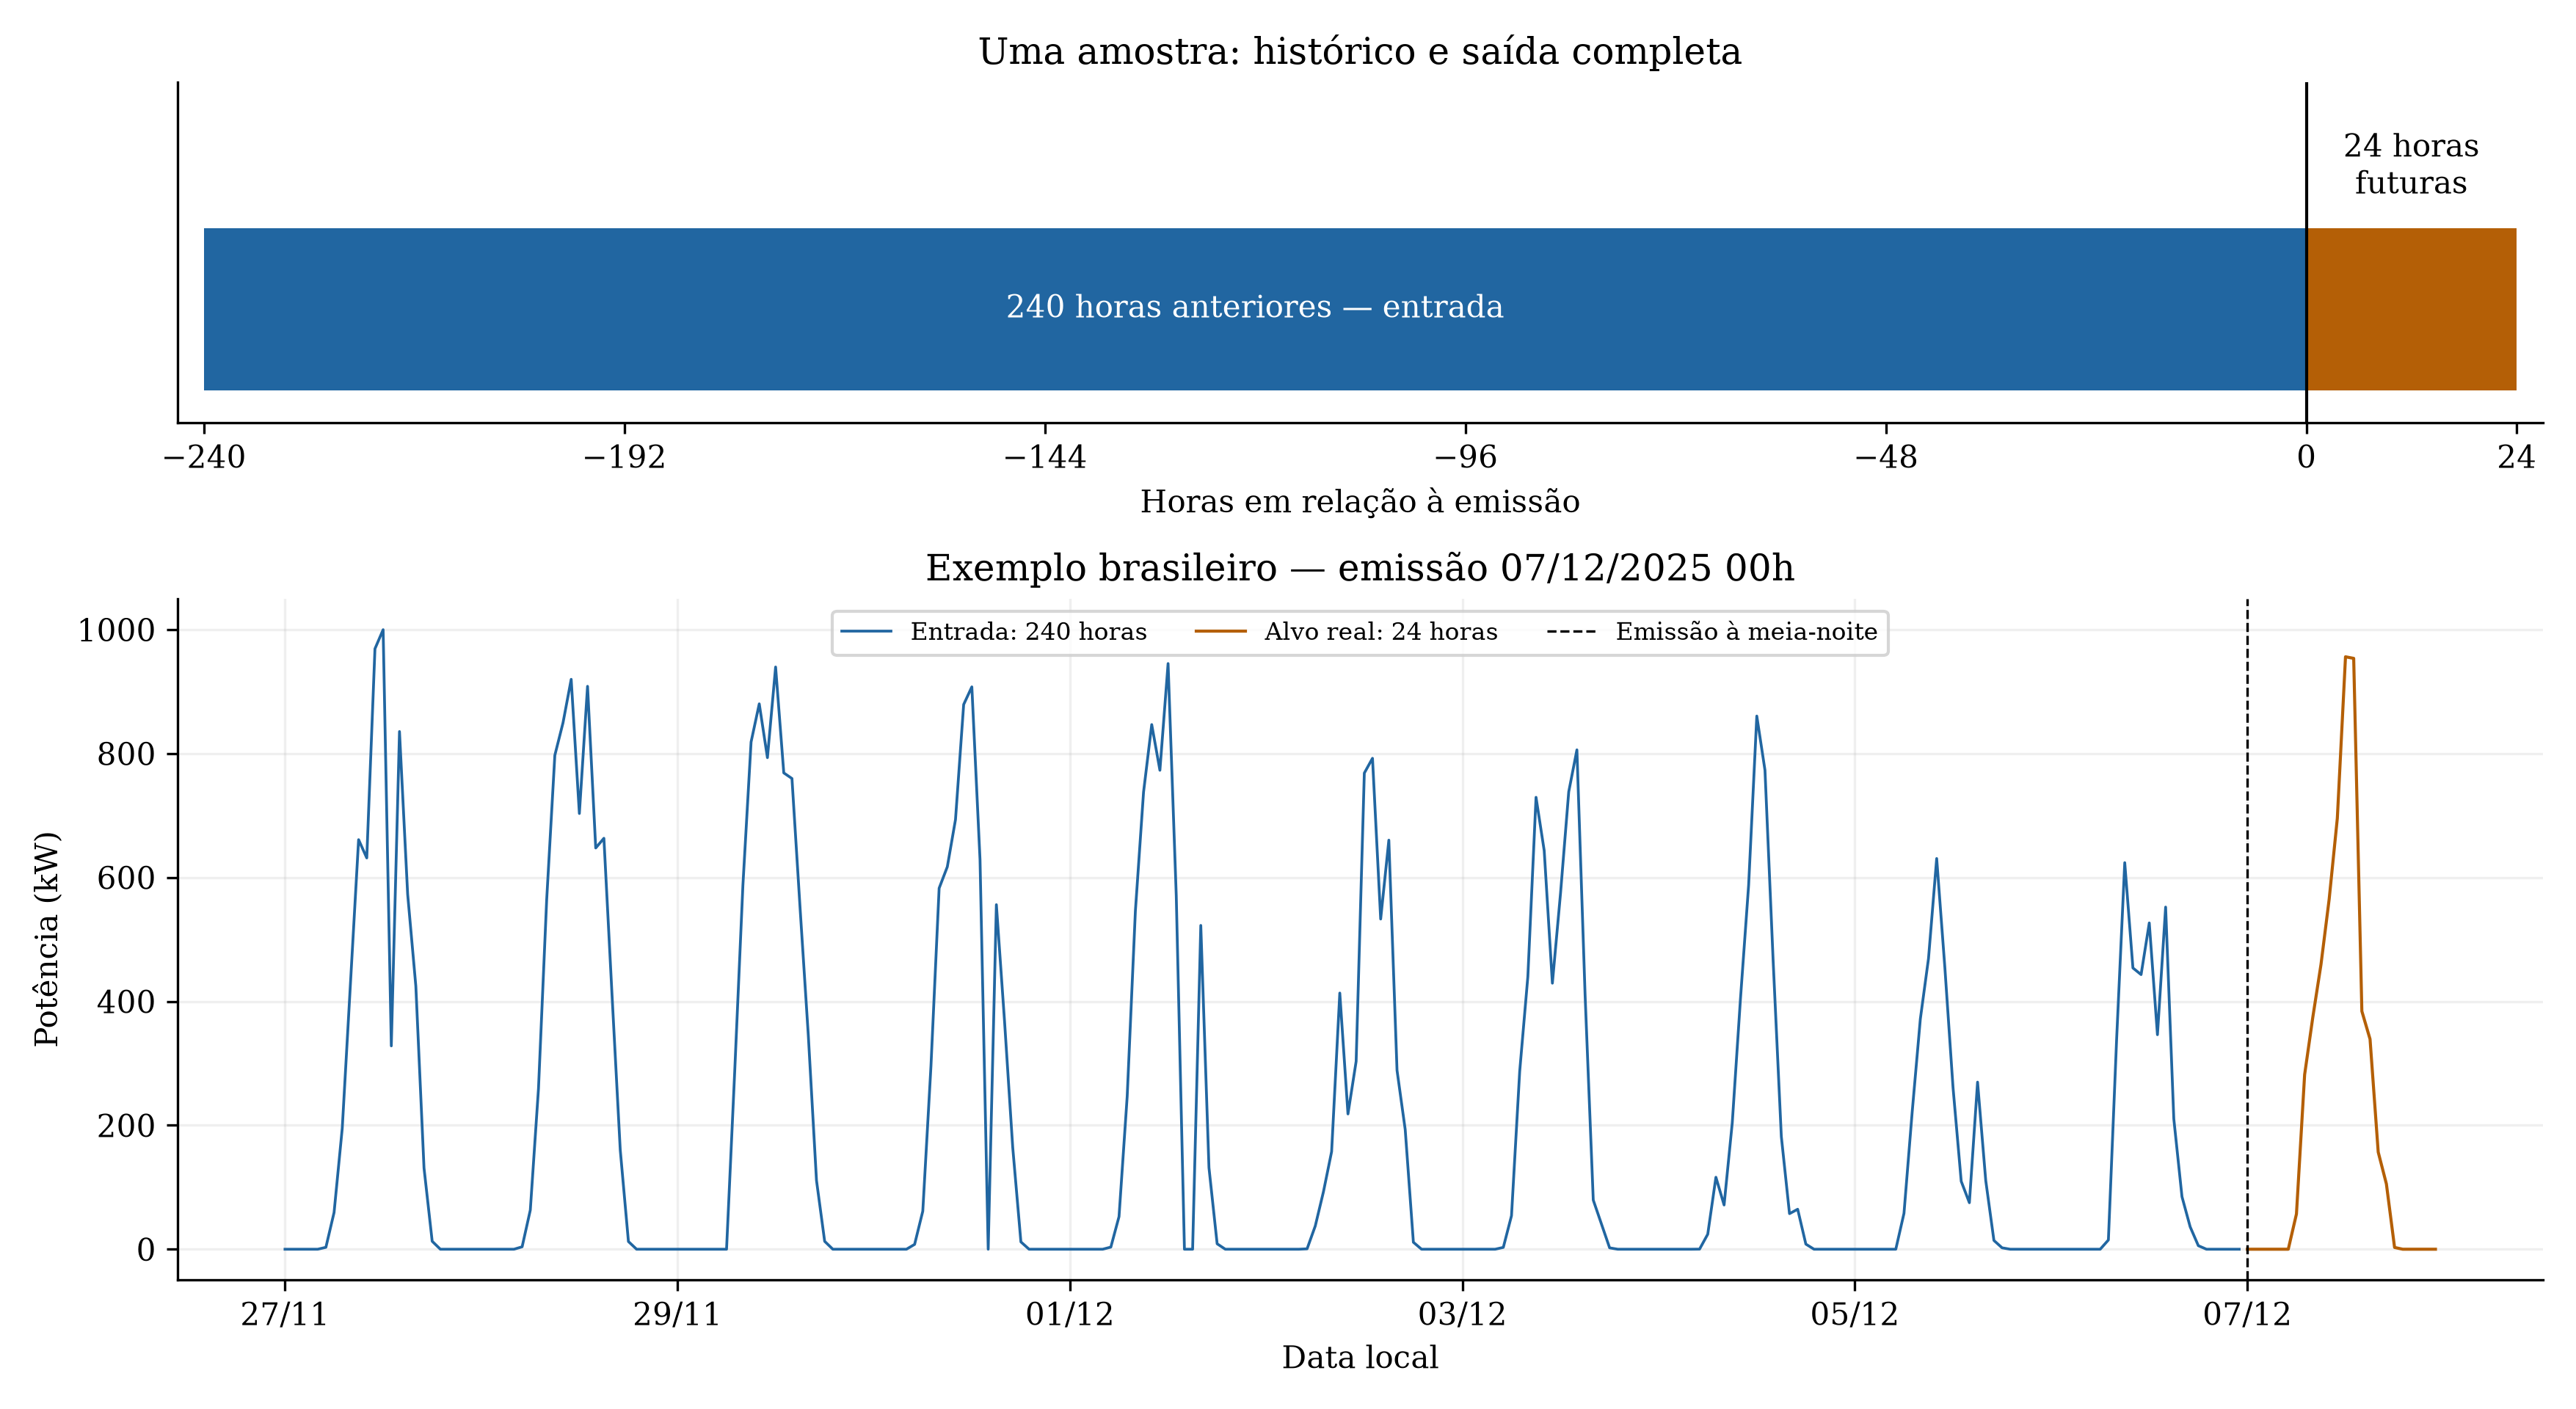

**Figura 04.01-1.** Histórico de 240 horas e vetor-alvo de 24 horas. Os dois trechos são dados reais preparados; não houve previsão. Fonte: elaboração própria.

In [7]:
figuras=[]
def salvar_figura(fig,nome,legenda):
    fig.tight_layout()
    for ext in ["png","pdf"]:
        fig.savefig(FIGURAS/f"{nome}.{ext}",dpi=300,facecolor="white")
    plt.close(fig)
    figuras.append(dict(arquivo=nome,legenda=legenda))
    display(Image(filename=str(FIGURAS/f"{nome}.png"),width=1100))
    display(Markdown(legenda))

fig,ax=plt.subplots(2,1,figsize=(11.7,6.4),gridspec_kw={'height_ratios':[1,2]})
ax[0].broken_barh([(-L,L)],(0,1),facecolors="#2166a1")
ax[0].broken_barh([(0,H)],(0,1),facecolors="#b45f06")
ax[0].axvline(0,color="black",lw=1)
ax[0].text(-L/2,.5,"240 horas anteriores — entrada",color="white",ha="center",va="center")
ax[0].text(H/2,1.15,"24 horas\nfuturas",ha="center",va="bottom")
ax[0].set(xlim=(-L-3,H+3),ylim=(-.2,1.9),xlabel="Horas em relação à emissão",yticks=[],
          xticks=[-240,-192,-144,-96,-48,0,24],title="Uma amostra: histórico e saída completa")
idx=selecionadas['brasil'].query("particao == 'teste'")
if idx.empty:idx=selecionadas['brasil']
if len(idx):
    e=idx.iloc[0];d=bases['brasil']
    hist=d.iloc[int(e.inicio_hist_pos):int(e.inicio_alvo_pos)]
    futuro=d.iloc[int(e.inicio_alvo_pos):int(e.fim_alvo_pos)+1]
    ax[1].plot(hist.index,hist.Active_Power,color="#2166a1",lw=.9,label="Entrada: 240 horas")
    ax[1].plot(futuro.index,futuro.Active_Power,color="#b45f06",lw=1,label="Alvo real: 24 horas")
    ax[1].axvline(e.emissao,color="black",ls="--",lw=.8,label="Emissão à meia-noite")
    ax[1].set(title=f"Exemplo brasileiro — emissão {e.emissao:%d/%m/%Y %Hh}",ylabel="Potência (kW)",xlabel="Data local")
    ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'));ax[1].legend(ncol=3,fontsize=8)
ax[1].grid(alpha=.2)
salvar_figura(fig,"fig_04_01_entrada_saida",
    "**Figura 04.01-1.** Histórico de 240 horas e vetor-alvo de 24 horas. Os dois trechos são dados reais preparados; não houve previsão. Fonte: elaboração própria.")

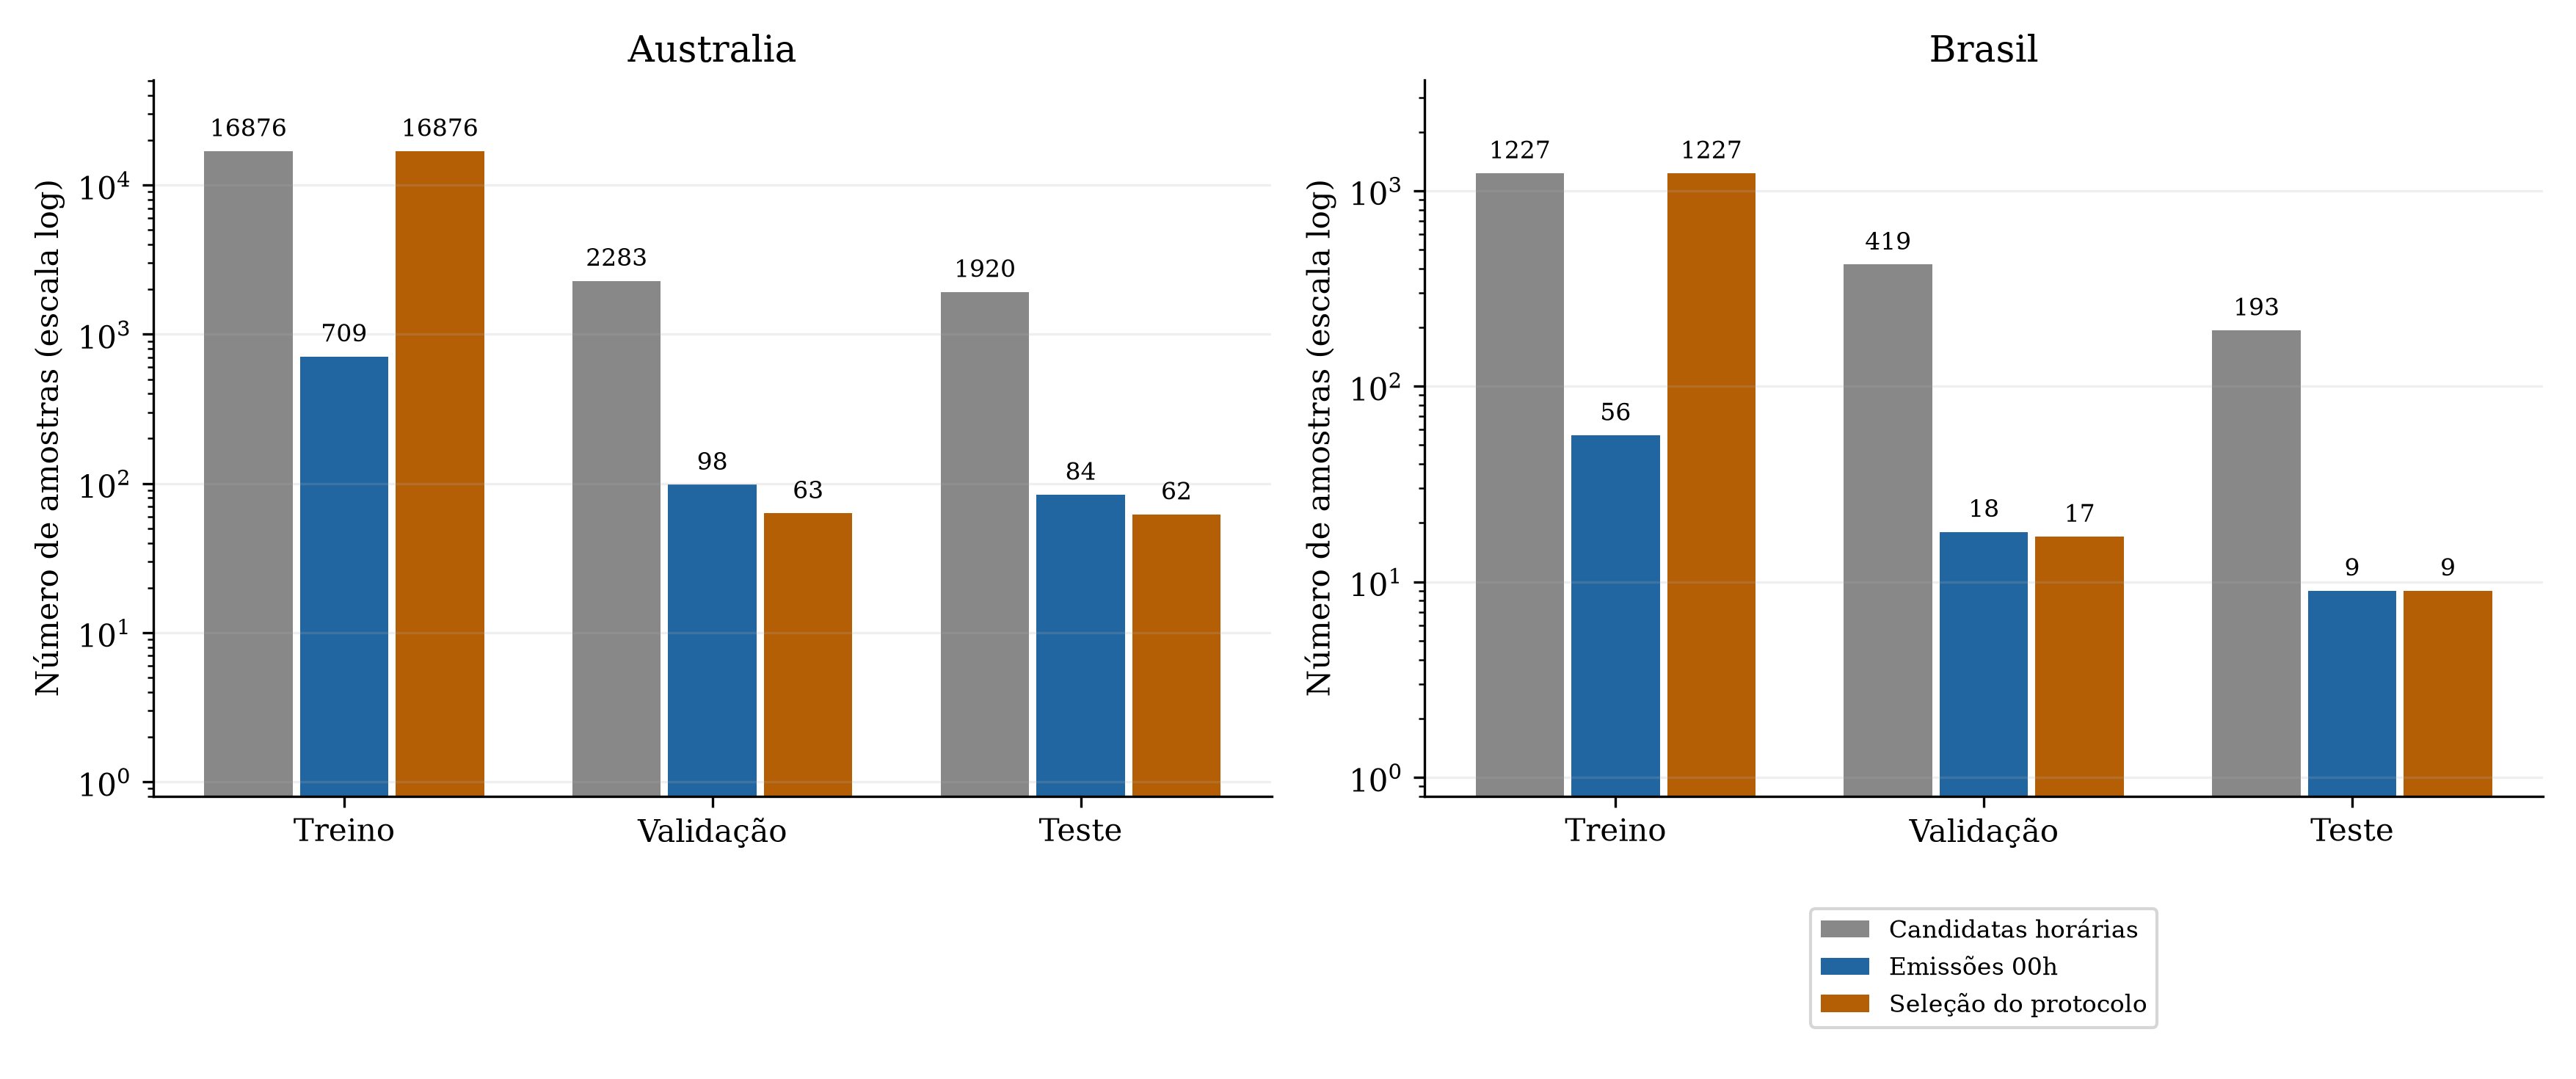

**Figura 04.01-2.** Candidatas e seleção final por partição. O treino usa passo de uma hora; validação/teste usam meia-noite e 24 alvos sem alteração. As barras se sobrepõem em significado e não devem ser somadas. Fonte: elaboração própria.

In [8]:
fig,axes=plt.subplots(1,2,figsize=(11.7,4.9))
for a,dom in zip(axes,['australia','brasil']):
    g=contagens.query("dominio == @dom").set_index('particao').reindex(['treino','validacao','teste'])
    x=np.arange(3)
    for desloc,col,label,cor in [(-.26,'candidatas_horarias','Candidatas horárias','#888888'),
                                (0,'emissoes_diarias','Emissões 00h','#2166a1'),
                                (.26,'selecionadas_protocolo','Seleção do protocolo','#b45f06')]:
        b=a.bar(x+desloc,g[col],width=.24,label=label,color=cor)
        a.bar_label(b,padding=3,fontsize=8)
    a.set_xticks(x,['Treino','Validação','Teste'])
    a.set_yscale('log');a.set_ylim(.8,max(g.candidatas_horarias.max(),1)*3)
    a.set(title=dom.capitalize(),ylabel='Número de amostras (escala log)');a.grid(axis='y',alpha=.2)
axes[1].legend(loc='upper center',bbox_to_anchor=(.5,-.14),fontsize=8,ncol=1)
salvar_figura(fig,"fig_04_02_contagem_janelas",
    "**Figura 04.01-2.** Candidatas e seleção final por partição. O treino usa passo de uma hora; validação/teste usam meia-noite e 24 alvos sem alteração. As barras se sobrepõem em significado e não devem ser somadas. Fonte: elaboração própria.")

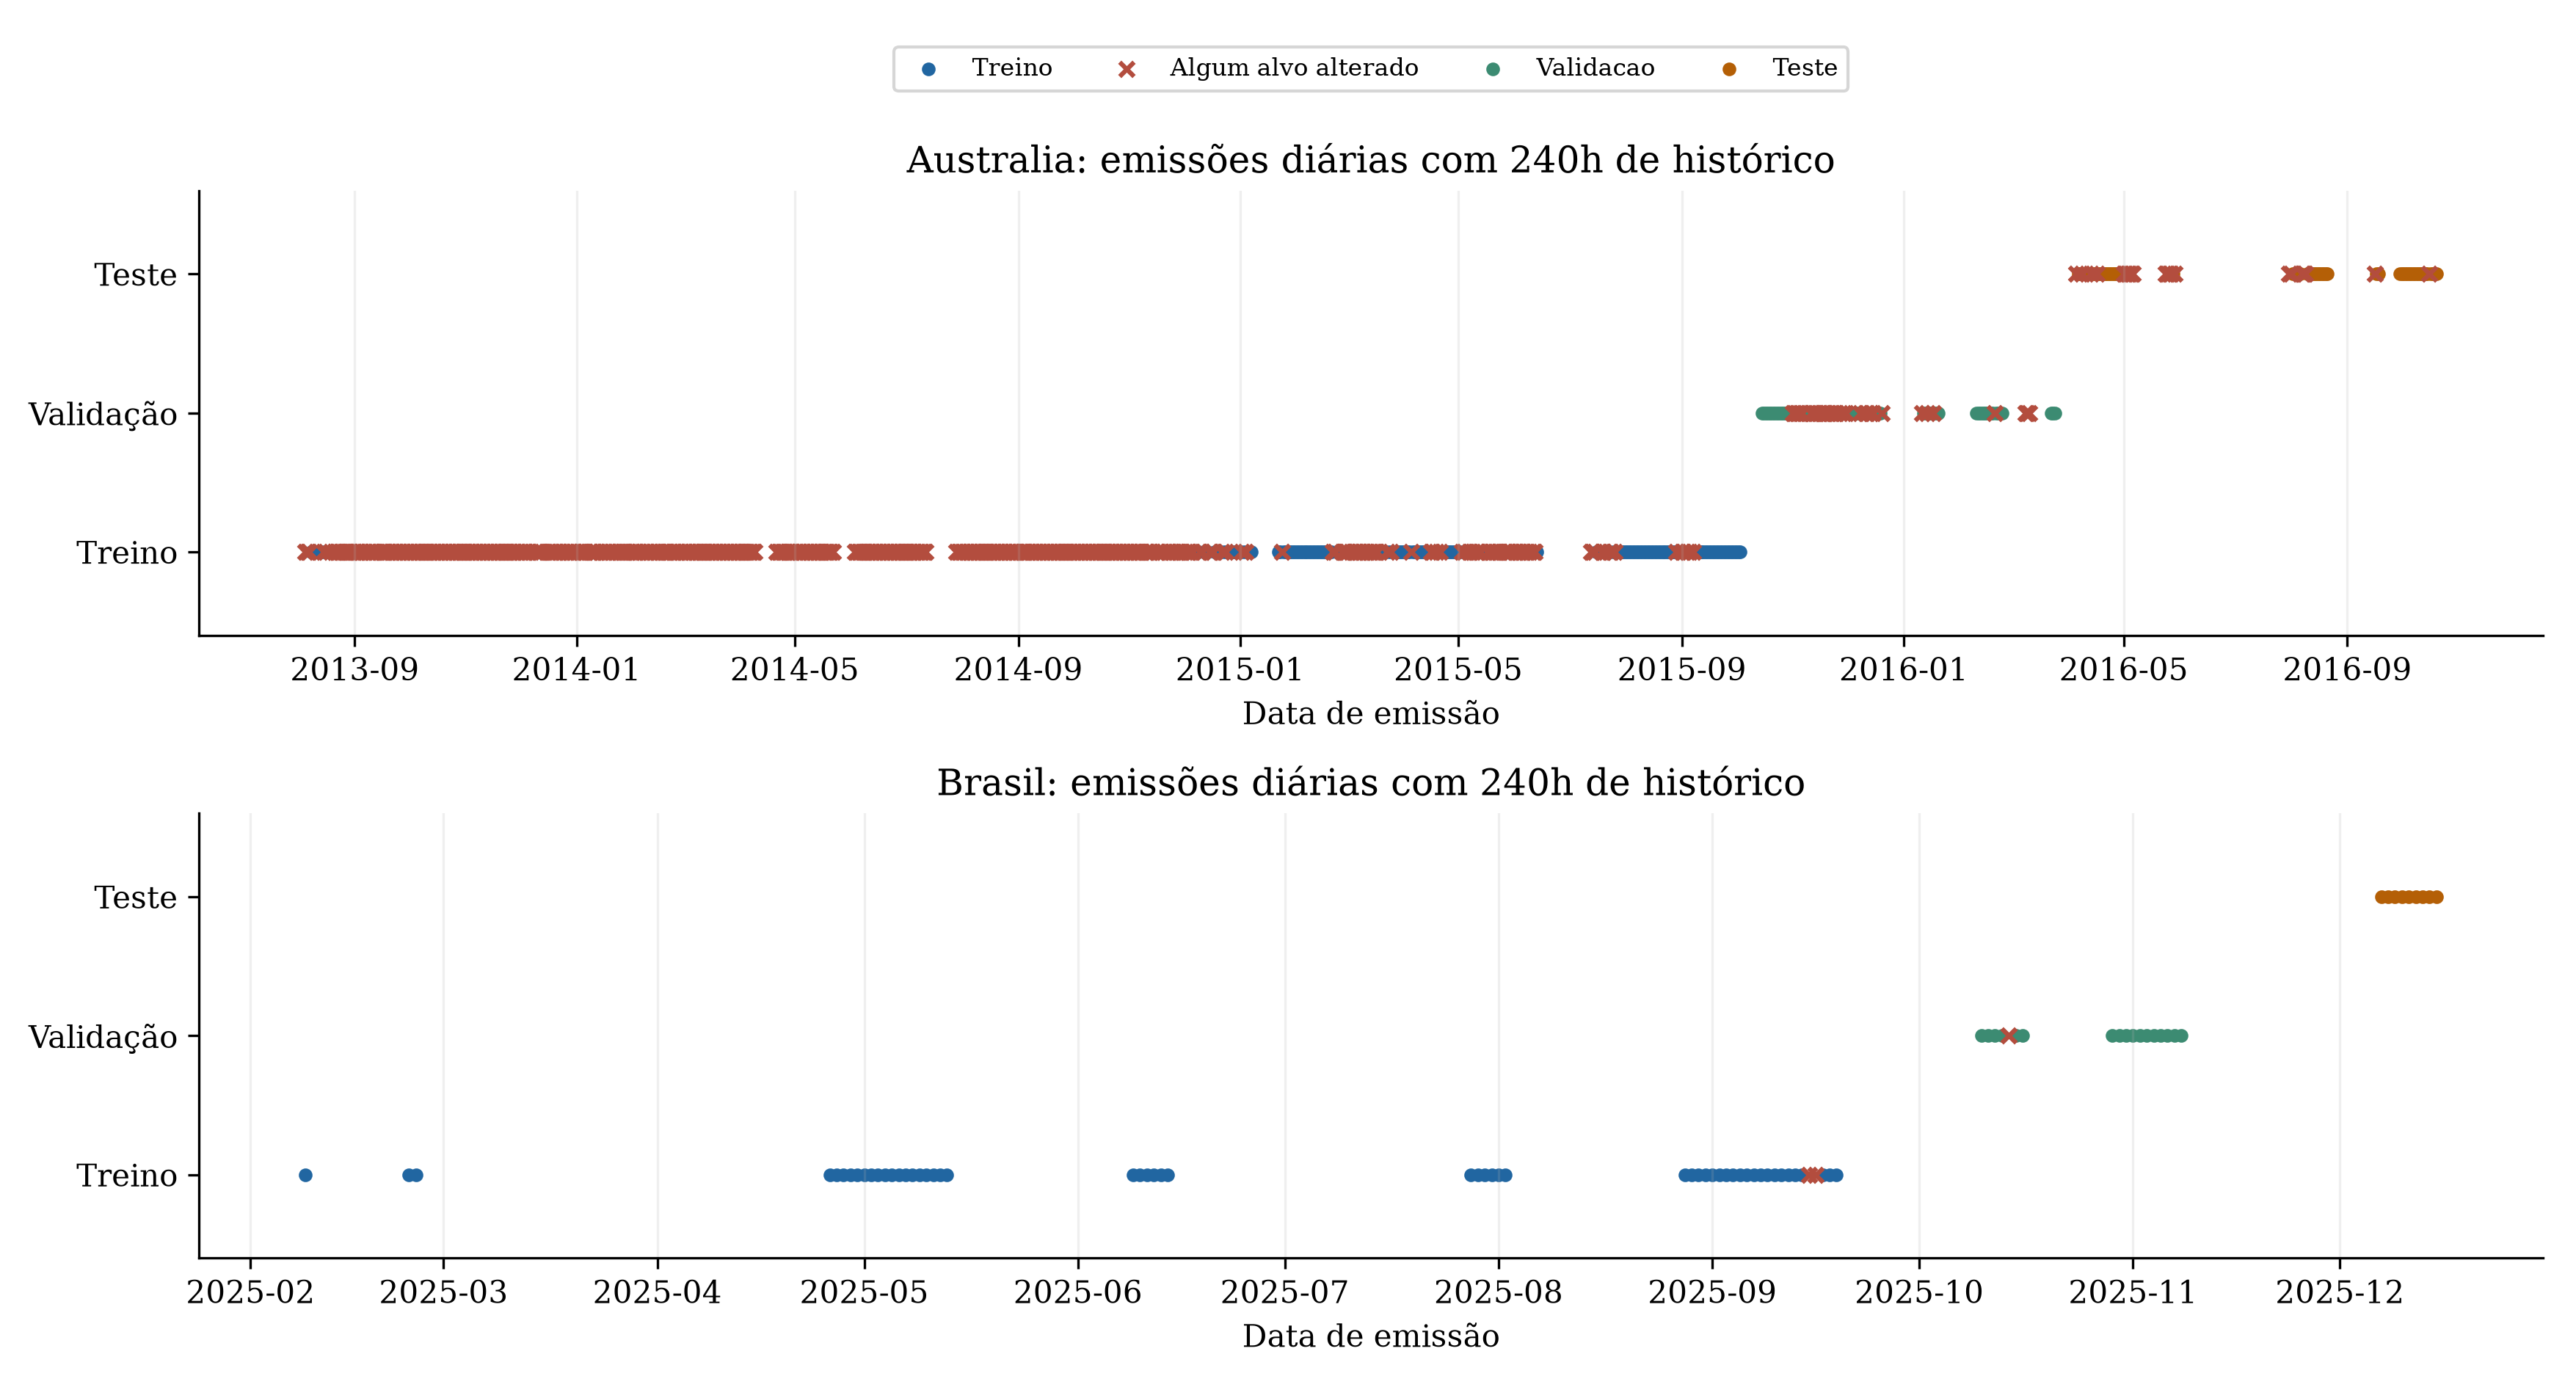

**Figura 04.01-3.** Datas das candidatas emitidas às 00h. Marcas vermelhas indicam ao menos uma potência-alvo alterada ou interpolada; são excluídas da validação/teste principais. No treino, mostram apenas o subconjunto diário de um conjunto treinável horário. Fonte: elaboração própria.

In [9]:
fig,axes=plt.subplots(2,1,figsize=(11.7,6.3))
cores={'treino':'#2166a1','validacao':'#3c8b72','teste':'#b45f06'}
for a,dom in zip(axes,['australia','brasil']):
    idx=indices[dom]
    for j,part in enumerate(['treino','validacao','teste']):
        diario=idx.loc[idx.particao.eq(part)&idx.historico_disponivel&idx.emissao_diaria]
        bom=diario.loc[diario.saida_total_observada]
        ruim=diario.loc[~diario.saida_total_observada]
        a.scatter(bom.emissao,np.full(len(bom),j),s=12,color=cores[part],label=part.capitalize())
        a.scatter(ruim.emissao,np.full(len(ruim),j),s=22,color='#b34d3e',marker='x',
                  label='Algum alvo alterado' if j==0 else None)
    a.set_yticks([0,1,2],['Treino','Validação','Teste'])
    a.set(title=dom.capitalize()+': emissões diárias com 240h de histórico',xlabel='Data de emissão')
    a.grid(axis='x',alpha=.2);a.margins(y=.3)
axes[0].legend(ncol=4,fontsize=8,loc='upper center',bbox_to_anchor=(.5,1.35))
salvar_figura(fig,"fig_04_03_calendario_emissoes",
    "**Figura 04.01-3.** Datas das candidatas emitidas às 00h. Marcas vermelhas indicam ao menos uma potência-alvo alterada ou interpolada; são excluídas da validação/teste principais. No treino, mostram apenas o subconjunto diário de um conjunto treinável horário. Fonte: elaboração própria.")

## 5. Verificação dos arquivos e uso posterior

Os `.npz` são carregados com `numpy.load(..., allow_pickle=False)`. Além de `X`, `X_potencia` e `y`, incluem timestamps dos 24 alvos, identificadores e máscaras. O Brasil também inclui, para cada alvo, as contagens de horas com oito contribuintes e com soma parcial.

No experimento posterior, o modelo produzirá uma saída de 24 valores por amostra. Para emitir o dia seguinte, fornece-se o histórico de 240 horas conhecido até a emissão; não são fornecidos AP ou meteorologia observados no futuro. O histórico univariado brasileiro pode ser usado pela MLP, LSTM ou TCN, com o ajuste de formato exigido pela arquitetura. O protocolo também permite comparar um Student australiano com o modelo local.

É necessário avaliar todos os modelos nas mesmas emissões, com persistência sazonal como referência, erros por horizonte e por dia e divisão cronológica. O número pequeno de dias brasileiros de teste deve acompanhar a interpretação das métricas. O ganho de transferência ou destilação só poderá ser afirmado depois desses experimentos.

In [10]:
verificacoes=[]
for dominio in FEATURES:
    d=bases[dominio]
    for part in ['treino','validacao','teste']:
        item=exportados[dominio+'_'+part]
        idx=selecionadas[dominio].query('particao == @part')
        with np.load(RAIZ/item['arquivo'],allow_pickle=False) as z:
            assert z['X'].shape==(len(idx),L,len(FEATURES[dominio]))
            assert z['y'].shape==(len(idx),H)
            assert np.isfinite(z['X']).all() and np.isfinite(z['y']).all()
            assert np.all(np.diff(z['timestamps_y'],axis=1)==np.timedelta64(1,'h'))
            assert np.all(z['timestamps_y'][:,0]==z['emissao'])
            assert np.all(z['timestamps_y'][:,-1]==z['emissao']+np.timedelta64(H-1,'h'))
            assert np.allclose(z['y']*capacidades[dominio],
                d.Active_Power.to_numpy()[idx.inicio_alvo_pos.to_numpy()[:,None]+np.arange(H)],rtol=1e-6,atol=1e-4)
            if part!='treino':assert z['mask_y_observado'].all()
            for campo in ['inicio_historico','inicio_alvo','fim_alvo']:
                r=d.reindex(idx[campo])
                assert np.array_equal(r.bloco_id.to_numpy(),idx.bloco_id.to_numpy())
                assert np.array_equal(r.particao_proposta.to_numpy(),idx.particao.to_numpy())
            verificacoes.append(dict(dominio=dominio,particao=part,amostras=len(idx),
                                     arquivo_reaberto=True,saida_24_horas=True))
for rel,h in fontes_hash.items():assert sha256(RAIZ/rel)==h, 'Uma fonte foi modificada.'
verificacoes=pd.DataFrame(verificacoes)
verificacoes.to_csv(TABELAS/'verificacoes.csv',index=False)
display(verificacoes)

,dominio,particao,amostras,arquivo_reaberto,saida_24_horas
0,australia,treino,16876,True,True
1,australia,validacao,63,True,True
2,australia,teste,62,True,True
3,brasil,treino,1227,True,True
4,brasil,validacao,17,True,True
5,brasil,teste,9,True,True


In [11]:
codigo = '\n\n'.join(''.join(c['source']) for c in json.loads(NOTEBOOK.read_text(encoding='utf-8'))['cells'] if c['cell_type']=='code')
manifesto = dict(config=CONFIG,features=FEATURES,entradas_comuns=['Active_Power'],
    capacidades_adotadas_kw=capacidades,
    referencia=dict(doi='10.1109/ACCESS.2025.3591040',tabela='5',
        gerador='https://github.com/gist-ailab/transfer-learning-PV-forecasting/blob/main/data_provider/data_loader.py'),
    adaptacoes=['Partições cronológicas herdadas do 03_03; histórico e alvo na mesma partição.',
        'Não atravessa blocos nem usa interpolações indisponíveis na emissão.',
        'Treino horário aceita alvos tratados com máscaras; validação/teste diários exigem 24 alvos sem alteração.',
        'AP em p.u. pela capacidade adotada; meteorologia com z-score ajustado somente no treino.',
        'Brasil univariado, Austrália com cinco variáveis; nenhuma arquitetura foi treinada ou transferida.'],
    fontes_sha256=fontes_hash,notebook=str(NOTEBOOK.relative_to(RAIZ)),
    codigo_sha256=hashlib.sha256(codigo.encode()).hexdigest(),tensores=exportados,
    contagens=contagens.to_dict(orient='records'))
(RELATORIO/'config.json').write_text(json.dumps(CONFIG,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
(RELATORIO/'manifesto.json').write_text(json.dumps(manifesto,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
(RELATORIO/'indice_figuras.json').write_text(json.dumps(figuras,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
(RELATORIO/'legendas_figuras.md').write_text('\n\n'.join(i['legenda'] for i in figuras)+'\n',encoding='utf-8')
br=contagens.query("dominio == 'brasil'").set_index('particao')
resumo = (f'# Estratégia 04.01: {L} horas de entrada e {H} horas de saída\n\n'
    'Treino: sliding window com passo de uma hora. Validação/teste: emissão diária às 00h, com 24 alvos sem alteração. '
    'Blocos, partições e disponibilidade das interpolações são respeitados.\n\n'
    f"Brasil: {int(br.loc['treino','selecionadas_protocolo'])} janelas horárias de treino, "
    f"{int(br.loc['validacao','selecionadas_protocolo'])} dias de validação e {int(br.loc['teste','selecionadas_protocolo'])} dias de teste. "
    'As amostras sobrepostas não são independentes. As contagens dependem das partições conservadoras herdadas.\n\n'
    'AU: X=(N,240,5); BR: X=(N,240,1); y=(N,24) nos dois domínios. X_potencia permite usar AP isoladamente na origem. '
    'Metadados de cobertura dos inversores não são entradas físicas adicionais.\n\n'
    'As capacidades são parâmetros adotados a confirmar; a unidade original do vento AU também requer confirmação. '
    'Este notebook não treina modelos e não altera as bases do 03_03.\n')
(RELATORIO/'resumo.md').write_text(resumo,encoding='utf-8')
display(Markdown(resumo))
print('Notebook:',NOTEBOOK)
print('Tensores:',TENSORES)
print('Relatórios:',RELATORIO)

Notebook: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\notebooks\tcc\04_01_estrategia_entrada_240h_24h.ipynb
Tensores: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\data\processed\janelas_240h_24h
Relatórios: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\04_01_estrategia_240h_24h


# Estratégia 04.01: 240 horas de entrada e 24 horas de saída

Treino: sliding window com passo de uma hora. Validação/teste: emissão diária às 00h, com 24 alvos sem alteração. Blocos, partições e disponibilidade das interpolações são respeitados.

Brasil: 1227 janelas horárias de treino, 17 dias de validação e 9 dias de teste. As amostras sobrepostas não são independentes. As contagens dependem das partições conservadoras herdadas.

AU: X=(N,240,5); BR: X=(N,240,1); y=(N,24) nos dois domínios. X_potencia permite usar AP isoladamente na origem. Metadados de cobertura dos inversores não são entradas físicas adicionais.

As capacidades são parâmetros adotados a confirmar; a unidade original do vento AU também requer confirmação. Este notebook não treina modelos e não altera as bases do 03_03.
